# ACA N.º 2 – Aprendizaje Automático
## Predicción del valor de viviendas con una red neuronal profunda (MLP)

**Pilar:** Ventas – sector inmobiliario  
**Continuidad ACA 1:** California Housing y predicción del valor de viviendas.  
**Integrantes:** Anyela María Torres Sánchez · Brandon Andrés Ardila Meta · Edwin Arturo Contreras Padua

### Objetivo
Construir un pipeline reproducible de aprendizaje profundo para estimar el valor medio de viviendas a partir de variables socioeconómicas y geográficas. Se integra exploración, almacenamiento SQL, preparación, entrenamiento, evaluación y artefactos para Streamlit.

> Nota metodológica: California Housing contiene 20.640 registros, ocho variables predictoras y una variable objetivo. La variable objetivo está expresada en unidades de USD 100.000. La entrega ACA 1 mencionaba 10 variables; aquí se utiliza la estructura real del dataset de scikit-learn.

## 1. Instalación e importaciones
Ejecute la celda siguiente en un entorno con conexión a internet la primera vez para descargar California Housing.

In [1]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn joblib sqlalchemy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, json, sqlite3, joblib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)


## 2. Carga, comprensión y exploración de datos (EDA)
Se descarga el conjunto California Housing desde la colección de datasets de scikit-learn. El conjunto es tabular, por lo que no requiere tokenización ni aumento de imágenes/texto.

In [3]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()
df.rename(columns={"MedHouseVal": "median_house_value"}, inplace=True)
feature_names = [c for c in df.columns if c != "median_house_value"]
print("Dimensiones:", df.shape)
display(df.head())
display(df.describe().T)
print("\\nNulos por columna:\\n", df.isna().sum())
print("Duplicados:", df.duplicated().sum())


Dimensiones: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,median_house_value
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
median_house_value,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


\nNulos por columna:\n MedInc                0
HouseAge              0
AveRooms              0
AveBedrms             0
Population            0
AveOccup              0
Latitude              0
Longitude             0
median_house_value    0
dtype: int64
Duplicados: 0


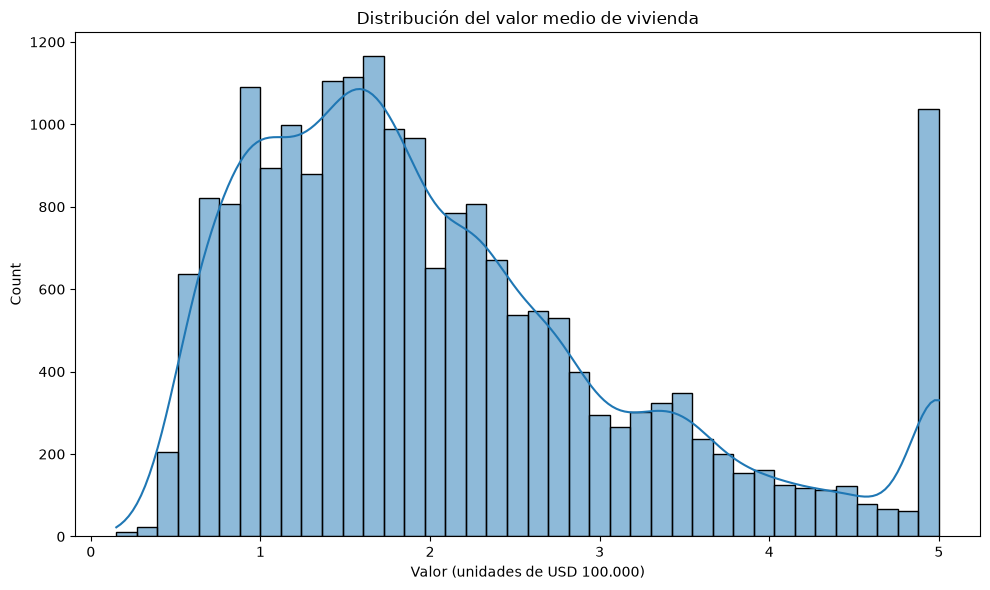

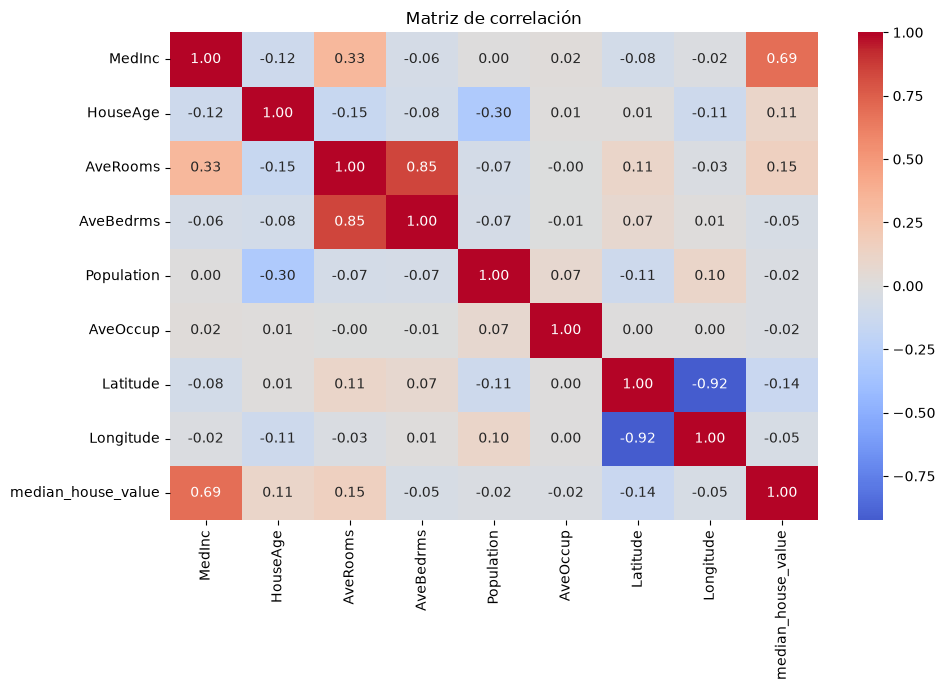

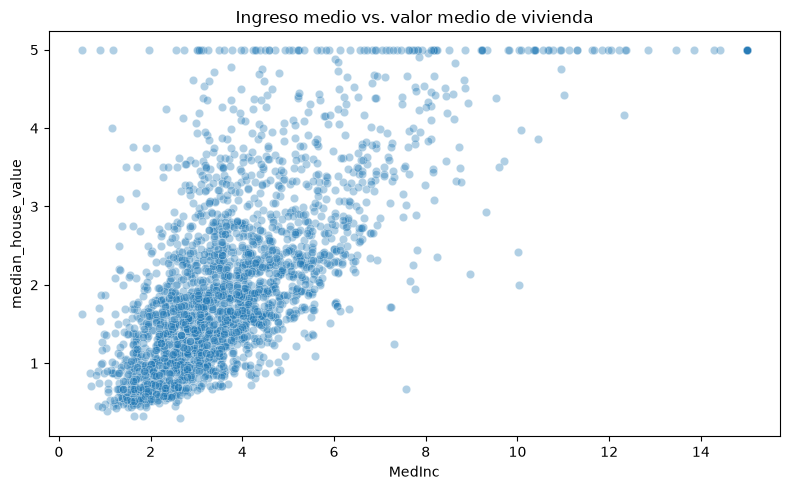

In [4]:
plt.figure(figsize=(10, 6))
sns.histplot(df["median_house_value"], bins=40, kde=True)
plt.title("Distribución del valor medio de vivienda")
plt.xlabel("Valor (unidades de USD 100.000)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df.sample(min(2500, len(df)), random_state=RANDOM_STATE),
                x="MedInc", y="median_house_value", alpha=.35)
plt.title("Ingreso medio vs. valor medio de vivienda")
plt.tight_layout()
plt.show()


## 3. Gestión SQL con SQLite
Se crea una base local `data/california_housing.db`, se inserta la tabla `housing` y se demuestra una consulta agregada. En proyectos reales, conviene registrar fecha de carga, procedencia y versión del dataset.

In [5]:
DB_PATH = Path("data/california_housing.db")
DB_PATH.parent.mkdir(exist_ok=True)
with sqlite3.connect(DB_PATH) as conn:
    df.to_sql("housing", conn, if_exists="replace", index=False)
    consulta = pd.read_sql_query(
        "SELECT COUNT(*) AS registros, AVG(median_house_value) AS promedio_objetivo FROM housing",
        conn
    )
display(consulta)
print("Base SQLite:", DB_PATH)


,registros,promedio_objetivo
0,20640,2.068558


Base SQLite: data\california_housing.db


## 4. Preparación y pipeline
- Se separa el objetivo `median_house_value` de las variables predictoras.
- Se realiza partición estratificada aproximada por cuantiles del objetivo: 80% entrenamiento y 20% prueba.
- Se estandarizan las variables de entrada para facilitar la optimización de la red.
- No se aplica aumento artificial de registros: en regresión tabular, agregar ruido sin una justificación del dominio puede crear ejemplos irreales y alterar la relación entre variables y precio. La estandarización y el control de partición constituyen el preprocesamiento aplicado.
- Se conserva un conjunto de prueba independiente para evaluar el desempeño final.

In [6]:
X = df[feature_names].copy()
y = df["median_house_value"].copy()

# Binning únicamente para distribuir de forma similar los rangos del objetivo.
y_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y_bins
)
print("Entrenamiento:", X_train.shape, "Prueba:", X_test.shape)


Entrenamiento: (16512, 8) Prueba: (4128, 8)


## 5. Modelado neuronal: MLP profundo
Se entrena una red neuronal *Multi-Layer Perceptron* con tres capas ocultas (128, 64 y 32 neuronas), activación ReLU y optimizador Adam. La función de pérdida es el error cuadrático medio (MSE). Se usa `early_stopping` para reducir el riesgo de sobreajuste.

La arquitectura MLP es apropiada para datos tabulares estructurados. No se utiliza CNN porque no hay imágenes; tampoco RNN/Transformer porque no hay secuencias ni texto.

In [7]:
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(128, 64, 32),
        activation="relu",
        solver="adam",
        alpha=0.001,
        batch_size=256,
        learning_rate_init=0.001,
        max_iter=250,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        random_state=RANDOM_STATE,
        verbose=False
    ))
])

mlp_pipeline.fit(X_train, y_train)
print("Iteraciones ejecutadas:", mlp_pipeline.named_steps["mlp"].n_iter_)
print("Mejor pérdida de validación:", mlp_pipeline.named_steps["mlp"].best_validation_score_)


Iteraciones ejecutadas: 104
Mejor pérdida de validación: 0.8127260496549249


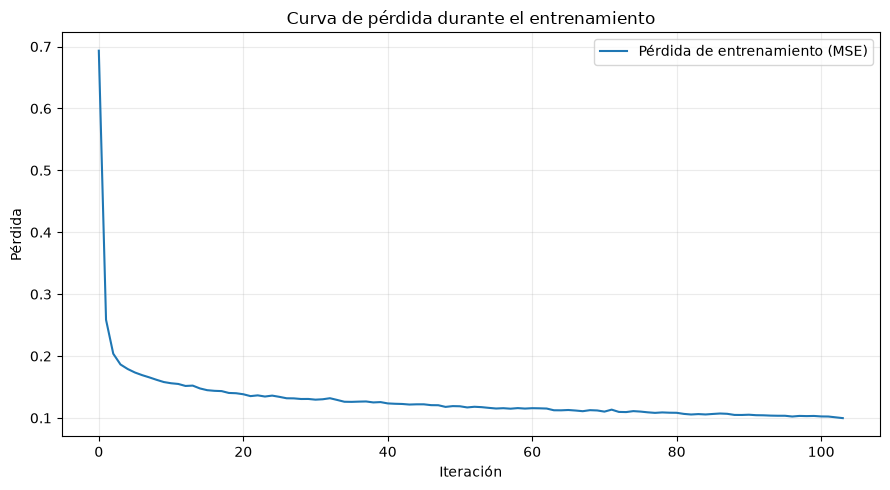

In [8]:
losses = mlp_pipeline.named_steps["mlp"].loss_curve_
plt.figure(figsize=(9, 5))
plt.plot(losses, label="Pérdida de entrenamiento (MSE)")
plt.title("Curva de pérdida durante el entrenamiento")
plt.xlabel("Iteración")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(alpha=.25)
plt.tight_layout()
plt.savefig(ARTIFACTS / "curva_perdida.png", dpi=150)
plt.show()


### 5.1 Curva de aprendizaje: entrenamiento vs. validación
Además de la pérdida de entrenamiento, se calcula una curva de aprendizaje con validación cruzada de 3 particiones. La curva compara el error cuadrático medio (MSE) de entrenamiento y de validación para distintos tamaños del conjunto de entrenamiento. Si ambas curvas se acercan al crecer los datos y la brecha es pequeña, el modelo no presenta un sobreajuste grave.

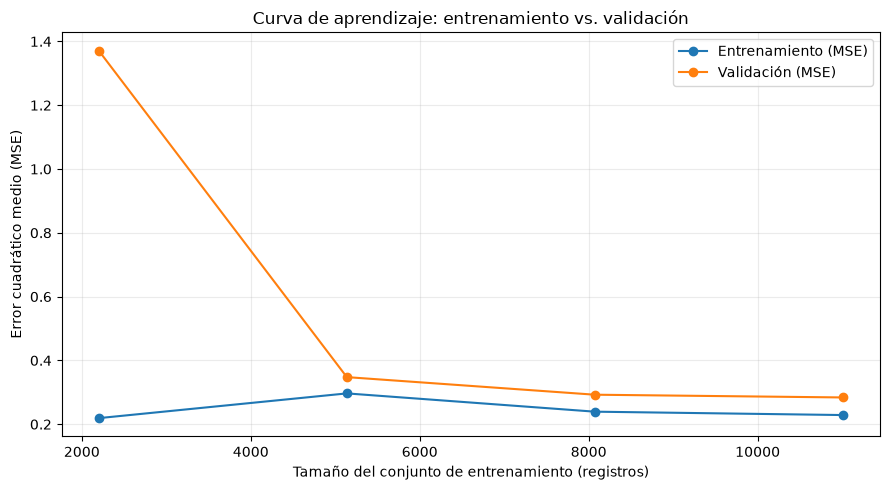

,train_sizes,MSE_entrenamiento,MSE_validacion
0,2201,0.219110,1.370917
1,5137,0.296628,0.347664
2,8072,0.239336,0.292534
3,11008,0.228753,0.283916


In [9]:
from sklearn.model_selection import learning_curve, KFold

train_sizes, train_scores, val_scores = learning_curve(
    mlp_pipeline, X_train, y_train,
    train_sizes=np.linspace(0.2, 1.0, 4),
    cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_mean_squared_error",
    n_jobs=1
)
train_mse = -train_scores.mean(axis=1)
val_mse = -val_scores.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_mse, "o-", label="Entrenamiento (MSE)")
plt.plot(train_sizes, val_mse, "o-", label="Validación (MSE)")
plt.title("Curva de aprendizaje: entrenamiento vs. validación")
plt.xlabel("Tamaño del conjunto de entrenamiento (registros)")
plt.ylabel("Error cuadrático medio (MSE)")
plt.legend()
plt.grid(alpha=.25)
plt.tight_layout()
plt.savefig(ARTIFACTS / "curva_aprendizaje.png", dpi=150)
plt.show()

display(pd.DataFrame({"train_sizes": train_sizes.astype(int), "MSE_entrenamiento": train_mse, "MSE_validacion": val_mse}))

## 6. Evaluación cuantitativa
Como el problema es de **regresión**, las métricas principales son MAE, RMSE y R². Accuracy, F1 y matriz de confusión corresponden a clasificación y no son métricas adecuadas para predecir un valor continuo. Se incluye un modelo Dummy como referencia mínima.

In [10]:
pred = mlp_pipeline.predict(X_test)
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)

metrics = {
    "MLP": {
        "MAE": float(mean_absolute_error(y_test, pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
        "R2": float(r2_score(y_test, pred))
    },
    "Dummy baseline": {
        "MAE": float(mean_absolute_error(y_test, pred_dummy)),
        "RMSE": float(np.sqrt(mean_squared_error(y_test, pred_dummy))),
        "R2": float(r2_score(y_test, pred_dummy))
    }
}
metrics_df = pd.DataFrame(metrics).T
display(metrics_df)
metrics_df.to_csv(ARTIFACTS / "metricas.csv", index=True)
with open(ARTIFACTS / "metricas.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)


,MAE,RMSE,R2
MLP,0.348924,0.523452,0.792372
Dummy baseline,0.909054,1.148784,-0.000019


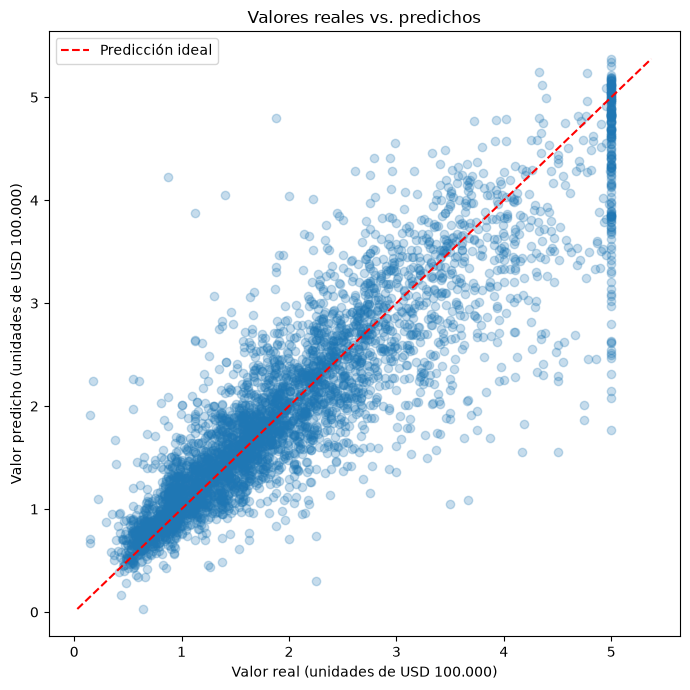

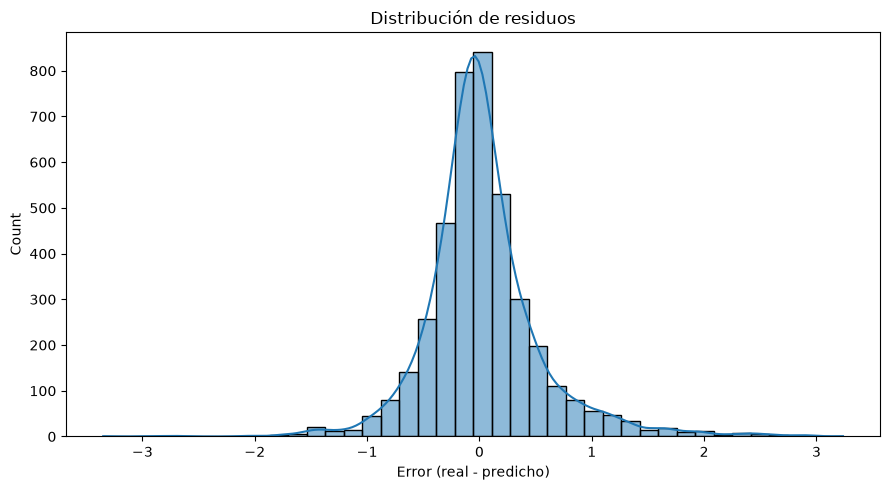

In [11]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, pred, alpha=.25)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lims, lims, "r--", label="Predicción ideal")
plt.xlabel("Valor real (unidades de USD 100.000)")
plt.ylabel("Valor predicho (unidades de USD 100.000)")
plt.title("Valores reales vs. predichos")
plt.legend()
plt.tight_layout()
plt.savefig(ARTIFACTS / "real_vs_predicho.png", dpi=150)
plt.show()

residuos = y_test - pred
plt.figure(figsize=(9, 5))
sns.histplot(residuos, bins=40, kde=True)
plt.title("Distribución de residuos")
plt.xlabel("Error (real - predicho)")
plt.tight_layout()
plt.savefig(ARTIFACTS / "residuos.png", dpi=150)
plt.show()


## 7. Guardado del modelo y metadatos para Streamlit
Se guarda el pipeline completo (escalador + red neuronal), nombres y orden de las variables, métricas y descripción de unidades. La aplicación utiliza estos artefactos para realizar inferencias sin volver a entrenar.

In [12]:
joblib.dump(mlp_pipeline, ARTIFACTS / "modelo_mlp_california.joblib")
metadata = {
    "features": feature_names,
    "target": "median_house_value",
    "target_units": "unidades de USD 100.000",
    "architecture": "MLPRegressor(hidden_layer_sizes=(128,64,32), activation='relu', solver='adam')",
    "random_state": RANDOM_STATE,
    "metrics": metrics
}
with open(ARTIFACTS / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)
print("Artefactos guardados en:", ARTIFACTS.resolve())


Artefactos guardados en: C:\Users\EACP\Downloads\Computacion_nube\Aca_2\ACA2_Redes_Neuronales_Grupo17_MEJORADO\ACA2_Redes_Neuronales_Grupo17\artifacts


## 8. Conclusiones y limitaciones
1. El pipeline integra EDA, persistencia SQL, preparación, entrenamiento, evaluación y exportación del modelo.
2. La red MLP aprende relaciones no lineales entre ingreso, ocupación, antigüedad, habitaciones y ubicación.
3. La comparación con Dummy permite comprobar si la red aporta valor predictivo frente a una referencia simple.
4. En el conjunto de prueba la red obtuvo MAE = 0.349, RMSE = 0.523 y R² = 0.792: explica cerca del 79 % de la variabilidad del valor medio y reduce el error absoluto del Dummy en aproximadamente 62 %. La curva de aprendizaje muestra si ese desempeño se mantiene al variar el tamaño de entrenamiento.
5. California Housing representa datos históricos de California; no debe utilizarse como avalúo profesional ni como estimación de precios actuales en Colombia.
6. Antes de un uso comercial real, se requieren datos recientes y locales, validación temporal/geográfica, monitoreo de deriva y evaluación de sesgos.

**Reproducibilidad:** semilla 42. Ejecutar el notebook de arriba hacia abajo. Los valores de las métricas se generan en la ejecución y no se inventan en este documento.